In [1]:
import pandas as pd
import re
from preproc import PARHAFPreprocessor

In [2]:
df = pd.read_parquet('data/train-00000-of-00001.parquet')

# Étape 1 : Préparation des données et Détection du Tabagisme
Ce notebook constitue la première étape de notre pipeline. L'objectif est de charger les comptes rendus médicaux bruts (format Parquet), de sélectionner les champs d'intérêt, de nettoyer le texte, puis d'appliquer une première passe de détection par mots-clés (Regex) pour repérer les documents mentionnant le tabac.

In [3]:
df.columns

Index(['id', 'local_id', 'specialty', 'author', 'reviewer', 'pool',
       'suggested_scenario', 'documents', 'structured_abstract'],
      dtype='str')

In [4]:
df.head()

,id,local_id,specialty,author,reviewer,pool,suggested_scenario,documents,structured_abstract
0,ANATOMOPATHOLOGIE-00001,00001,ANATOMOPATHOLOGIE,ADU,CJA,General,"{'name': 'Chantale Peruchon', 'age': {'value':...","{'type': ['ANAPATH'], 'header': ['COMPTE-RENDU...","{'primary_diagnosis': None, 'primary_procedure..."
1,ANATOMOPATHOLOGIE-00002,00002,ANATOMOPATHOLOGIE,ADU,CJA,General,"{'name': 'Colette Lorilleux', 'age': {'value':...","{'type': ['ANAPATH'], 'header': ['COMPTE-RENDU...","{'primary_diagnosis': None, 'primary_procedure..."
2,ANATOMOPATHOLOGIE-00003,00003,ANATOMOPATHOLOGIE,ADU,CJA,General,"{'name': 'Kaena Koska', 'age': {'value': 69, '...","{'type': ['ANAPATH'], 'header': ['COMPTE-RENDU...","{'primary_diagnosis': None, 'primary_procedure..."
3,ANATOMOPATHOLOGIE-00004,00004,ANATOMOPATHOLOGIE,ADU,CJA,General,"{'name': 'Annette Tournoux', 'age': {'value': ...","{'type': ['ANAPATH'], 'header': ['COMPTE-RENDU...","{'primary_diagnosis': None, 'primary_procedure..."
4,ANATOMOPATHOLOGIE-00005,00005,ANATOMOPATHOLOGIE,ADU,CJA,General,"{'name': 'Elisabeta Riaud', 'age': {'value': 7...","{'type': ['ANAPATH'], 'header': ['COMPTE-RENDU...","{'primary_diagnosis': None, 'primary_procedure..."


## 1.1 Exploration initiale des données
Aperçu des variables disponibles et de la structure du jeu de données brut.

In [5]:
df = df[["id", "specialty", "documents"]]

In [6]:
preproc = PARHAFPreprocessor()

## 1.2 Prétraitement et Nettoyage du texte
Nous isolons les colonnes utiles à la classification. Ensuite, nous instancions notre pipeline personnalisé `PARHAFPreprocessor` pour :
1. Extraire le texte contenu dans les dictionnaires imbriqués (`explode_cols`).
2. Nettoyer les caractères spéciaux et formater le texte (`clean_text`).
3. Afficher les statistiques globales de distribution des mots et des spécialités médicales.

Statistiques des word_count
count    6185.000000
mean      450.224091
std       333.237084
min        20.000000
25%       223.000000
50%       367.000000
75%       581.000000
max      3481.000000
Name: word_count, dtype: float64

Repartition par spécialité
specialty
CHIRURGIE VISCERALE           849
CHIR ORTHO ET TRAUMATO        680
GYNECOLOGIE                   594
PNEUMOLOGIE                   531
CANCERO ADULTE                507
UROLOGIE                      497
ANATOMOPATHOLOGIE             438
OBSTETRIQUE                   322
MALADIES INFECTIEUSES         285
NEUROLOGIE                    251
MEDECINE INTERNE              228
HEPATO-GASTRO-ENTERO          170
MEDECINE GERIATRIQUE          155
HEMATOLOGIE CLINIQUE          153
CHIR.CARDIO-VASC.             117
NEPHROLOGIE                   104
CARDIOLOGIE                    96
MEDECINE INTER-SPECIALITES     82
MEDECINE PEDIATRIQUE           82
REANIMATION                    44
Name: count, dtype: int64


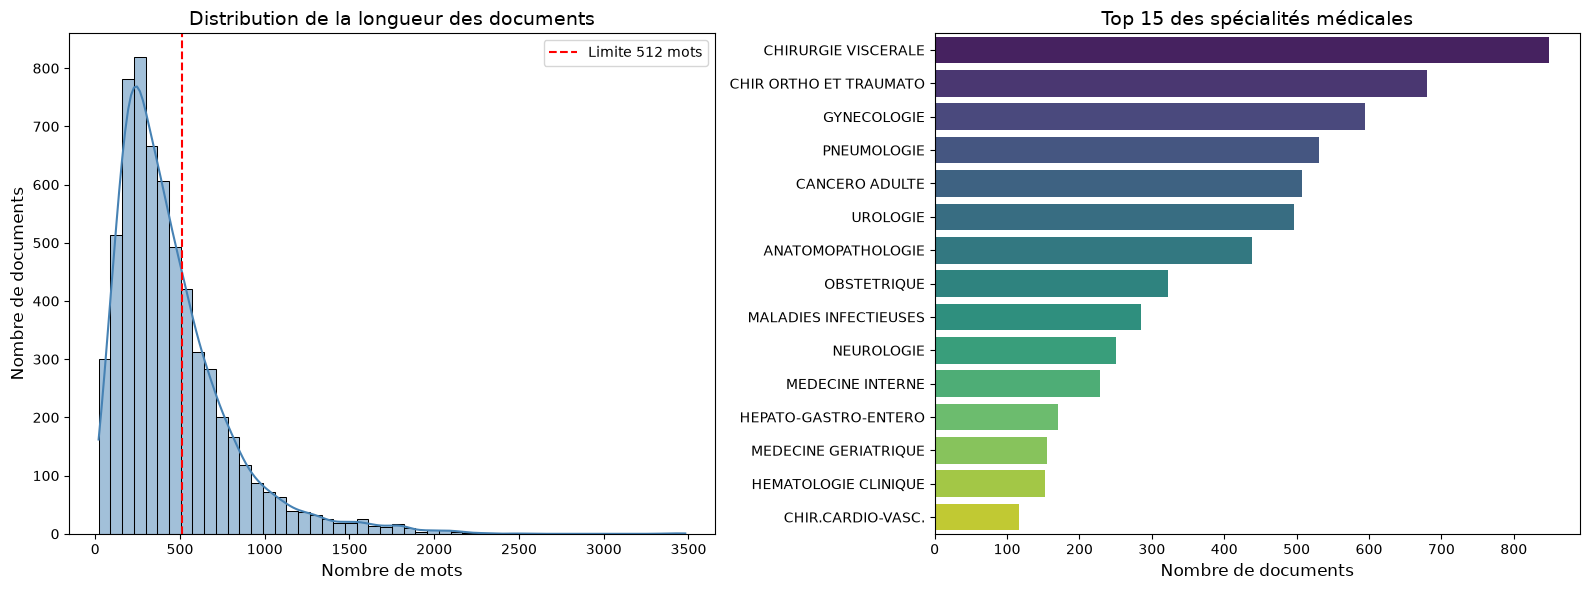

In [7]:
df = preproc.explode_cols(df)
df = preproc.clean_text(df)
preproc.stats(df)

## 1.3 Filtrage par expressions régulières (Regex)
Application de notre dictionnaire de mots-clés pour cibler les documents faisant explicitement mention du statut tabagique. Le jeu de données ainsi filtré est ensuite sauvegardé pour l'étape d'annotation et de modélisation.

c:\Users\Ce PC\Desktop\stage_m2\preproc.py:94: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_temp['mention_tabac'] = df_temp['text'].str.contains(


Documents avec mention du tabac (selon les mots-clés de la doc des M1) : 2780 sur 6185 (44.9%)


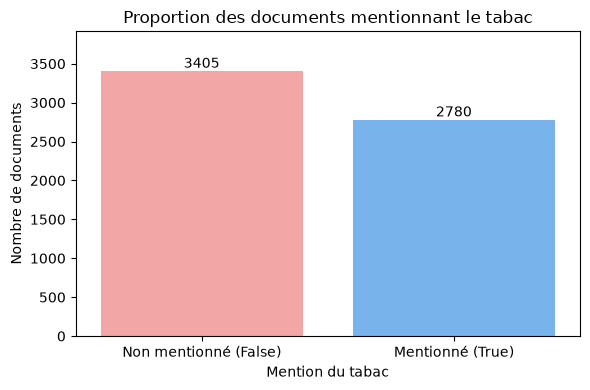

In [8]:
df = preproc.detecter_mentions(df)

In [9]:
df.to_csv("./data/df_preproc.csv", sep=",")